In [15]:
# Pick up edits to `.py` files without restarting kernel
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
# Import libraries
import cv2 as cv

In [17]:
# Import modules
import config
from pipeline import (
    apply_detector,
    apply_estimator,
    apply_filter,
    apply_matcher,
    build_detector,
    build_estimator,
    build_filter,
    build_matcher,
)
from utils import (
    center_crop_to_size,
    draw_keypoints,
    grab_frame,
    load_image,
    overlay_image,
    plot_image,
    plot_image_row,
    plot_matches,
    plot_outline,
    project_corners,
    select_best_matches,
    select_inlier_matches,
    shrink_to_max_side,
    warp_image,
)

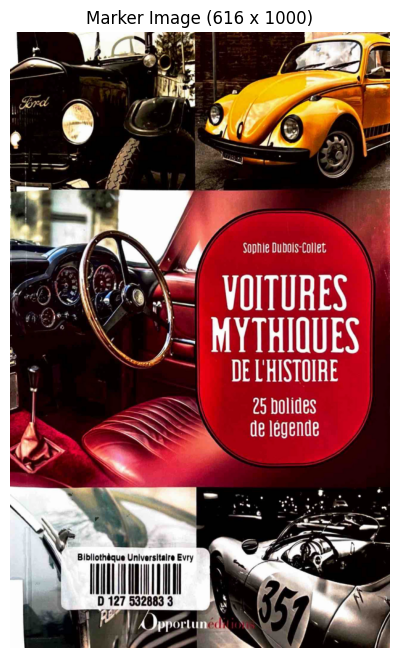

In [18]:
# Marker image
marker = load_image(config.MARKER_PATH)
marker = shrink_to_max_side(marker, config.MARKER_MAX_SIDE)
plot_image(marker, f"Marker Image ({marker.shape[1]} x {marker.shape[0]})")

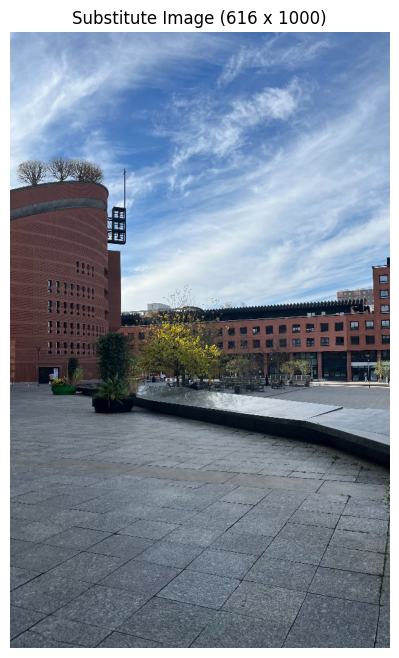

In [19]:
# Substitute image
substitute = load_image(config.SUBSTITUTE_PATH)
substitute = center_crop_to_size(substitute, marker.shape[1], marker.shape[0])
plot_image(
    substitute, f"Substitute Image ({substitute.shape[1]} x {substitute.shape[0]})"
)

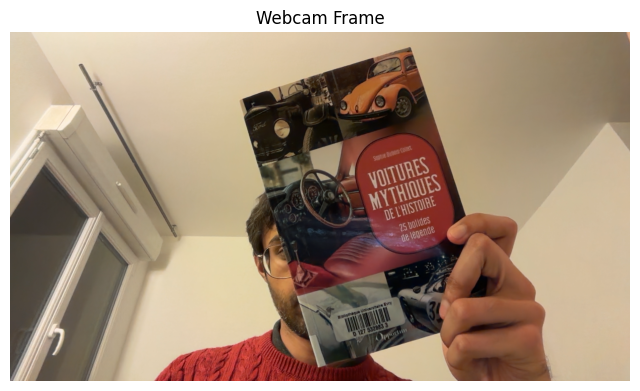

In [20]:
# Camera frame
if config.CAPTURE_NEW_FRAME:
    cv.imwrite(config.FRAME_PATH, grab_frame(config.CAMERA_INDEX))
frame = load_image(config.FRAME_PATH)
plot_image(frame, "Webcam Frame")

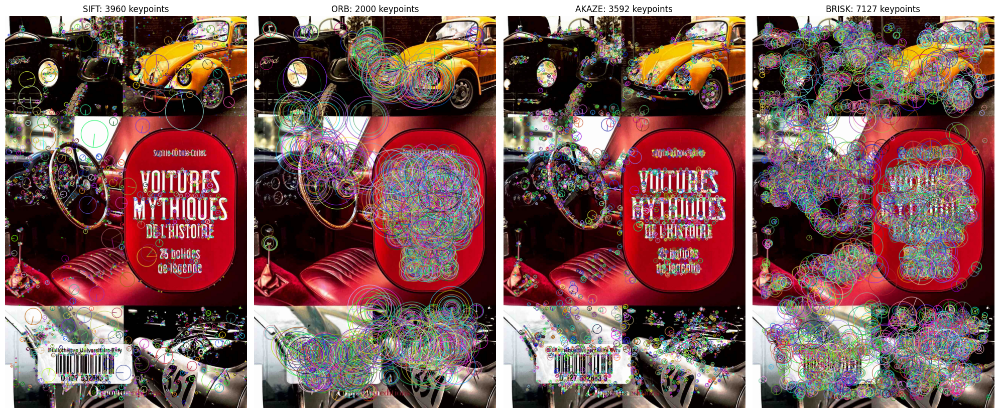

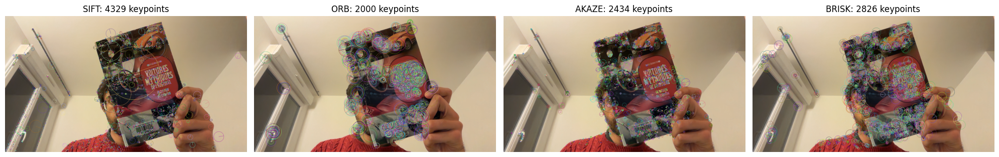

In [ ]:
# Image descriptor extraction: every registered detector
marker_features = {}
frame_features = {}

# One drawn image and one title per detector, for the side by side plots
marker_keypoint_images = []
marker_keypoint_titles = []
frame_keypoint_images = []
frame_keypoint_titles = []

for detector_name in config.DETECTORS:
    detector = build_detector(detector_name)

    # Marker keypoints
    marker_keypoints, marker_descriptors = apply_detector(detector, marker)
    marker_features[detector_name] = (marker_keypoints, marker_descriptors)
    marker_keypoint_images.append(draw_keypoints(marker, marker_keypoints))
    marker_keypoint_titles.append(f"{detector_name}: {len(marker_keypoints)} keypoints")

    # Frame keypoints
    frame_keypoints, frame_descriptors = apply_detector(detector, frame)
    frame_features[detector_name] = (frame_keypoints, frame_descriptors)
    frame_keypoint_images.append(draw_keypoints(frame, frame_keypoints))
    frame_keypoint_titles.append(f"{detector_name}: {len(frame_keypoints)} keypoints")

plot_image_row(marker_keypoint_images, marker_keypoint_titles)
plot_image_row(frame_keypoint_images, frame_keypoint_titles)

# The later cells still run on one detector for now
marker_keypoints, marker_descriptors = marker_features[config.DETECTOR_NAME]
frame_keypoints, frame_descriptors = frame_features[config.DETECTOR_NAME]

3960 marker descriptors matched


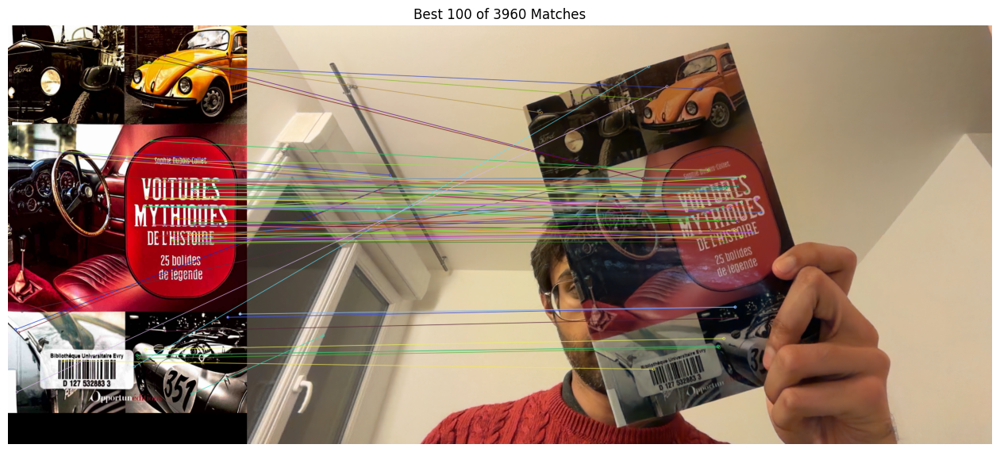

In [22]:
# Descriptor matching
matcher = build_matcher(config.MATCHER_NAME, config.DETECTOR_NAME)
knn_matches = apply_matcher(matcher, marker_descriptors, frame_descriptors)
print(f"{len(knn_matches)} marker descriptors matched")

# Plot only the closest matches
best_matches = select_best_matches(knn_matches)
shown_match_count = 100
plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    best_matches[:shown_match_count],
    f"Best {shown_match_count} of {len(best_matches)} Matches",
)

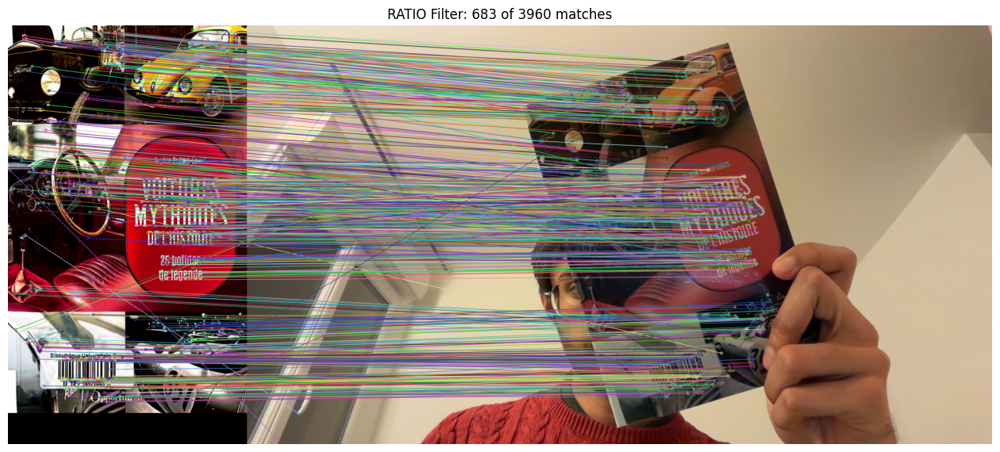

In [23]:
# Match filtering
match_filter = build_filter(config.FILTER_NAME)
good_matches = apply_filter(match_filter, knn_matches)
plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    good_matches,
    f"{config.FILTER_NAME} Filter: {len(good_matches)} of {len(knn_matches)} matches",
)

[[ 8.41256621e-01  2.27781960e-01  7.09801219e+02]
 [-2.76327405e-01  8.09142608e-01  2.08695156e+02]
 [-2.70095426e-05 -1.79531127e-05  1.00000000e+00]]


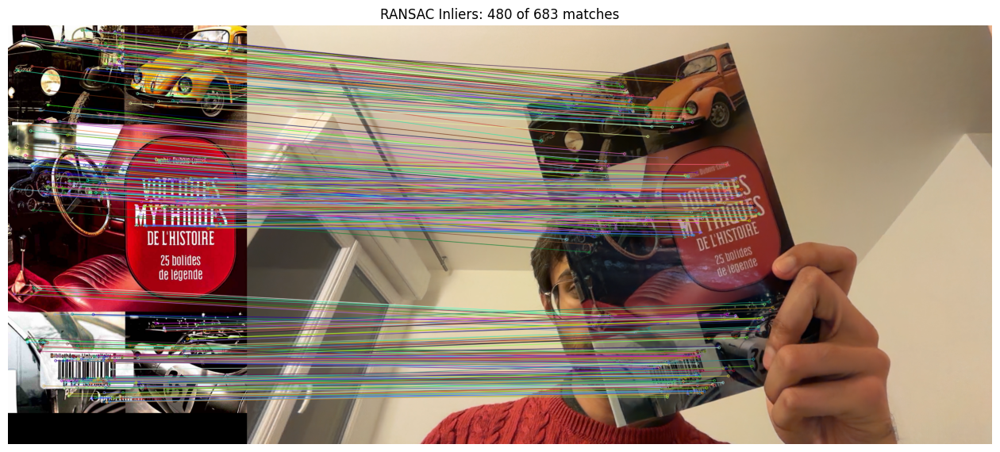

In [24]:
# Homography estimation
estimator = build_estimator(config.ESTIMATOR_NAME)
homography, inlier_mask = apply_estimator(
    estimator, marker_keypoints, frame_keypoints, good_matches
)
print(homography)

# Plot only the matches that agree with the homography
inlier_matches = select_inlier_matches(good_matches, inlier_mask)
plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    inlier_matches,
    f"{config.ESTIMATOR_NAME} Inliers: {len(inlier_matches)} of {len(good_matches)} matches",
)

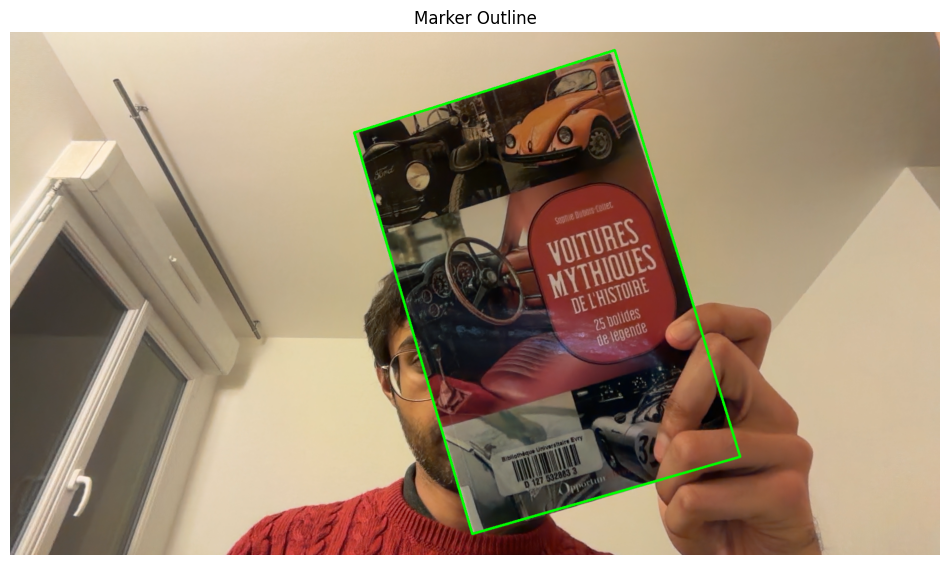

In [25]:
# Marker outline
frame_corners = project_corners(homography, marker)
plot_outline(frame, frame_corners, "Marker Outline", 12)

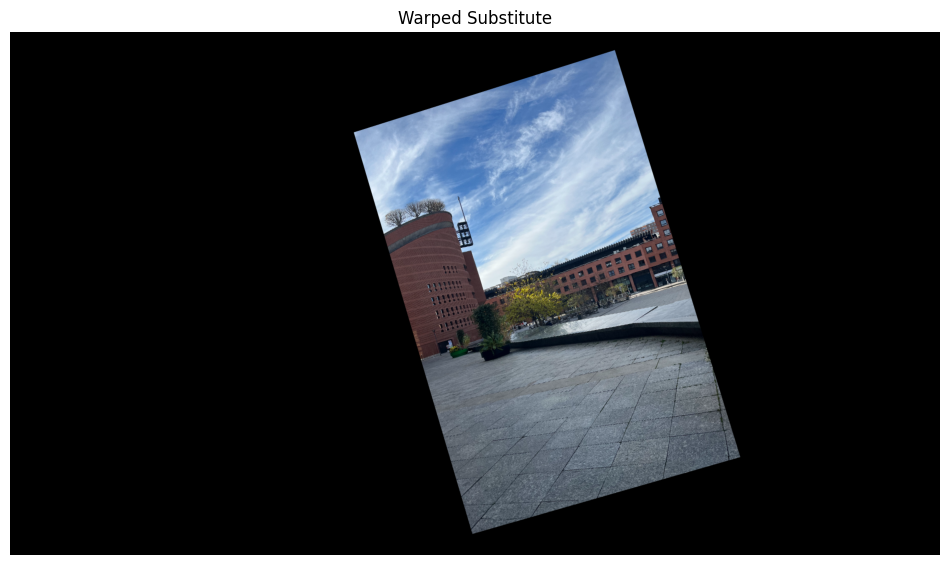

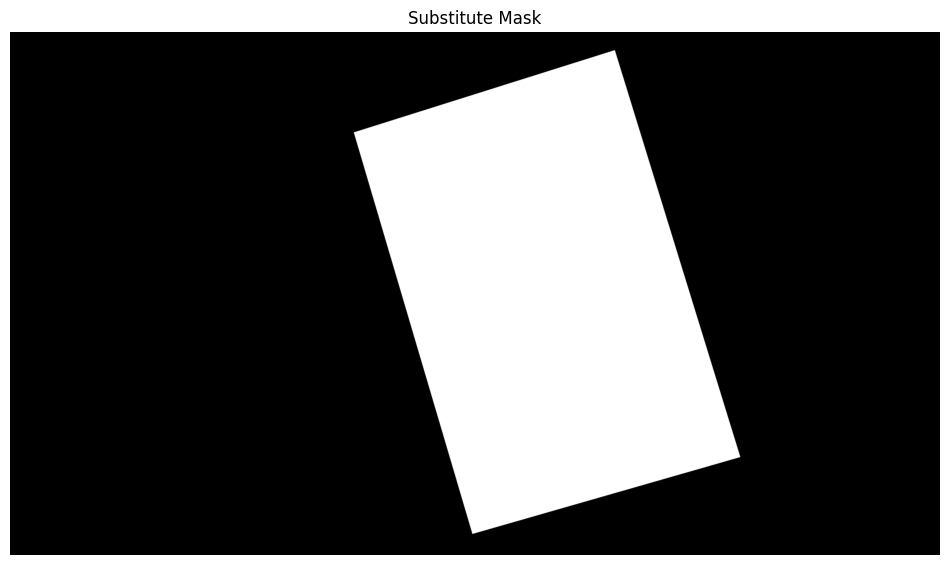

In [26]:
# Substitute warp
frame_height, frame_width = frame.shape[:2]
warped_substitute, substitute_mask = warp_image(
    substitute, homography, frame_width, frame_height
)
plot_image(warped_substitute, "Warped Substitute", 12)
plot_image(substitute_mask, "Substitute Mask", 12)

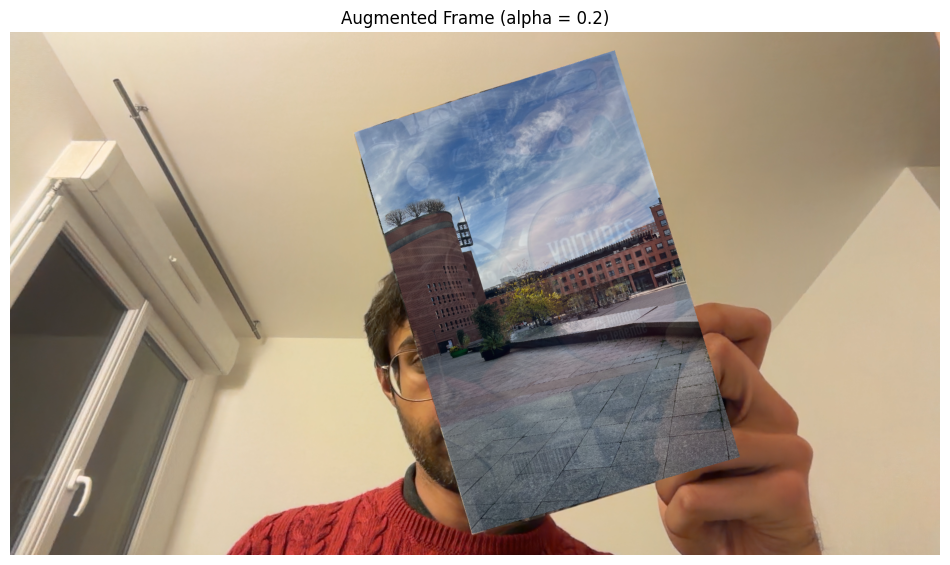

In [27]:
# Augmented frame
augmented_frame = overlay_image(
    frame, warped_substitute, substitute_mask, config.FRAME_ALPHA
)
plot_image(augmented_frame, f"Augmented Frame (alpha = {config.FRAME_ALPHA})", 12)

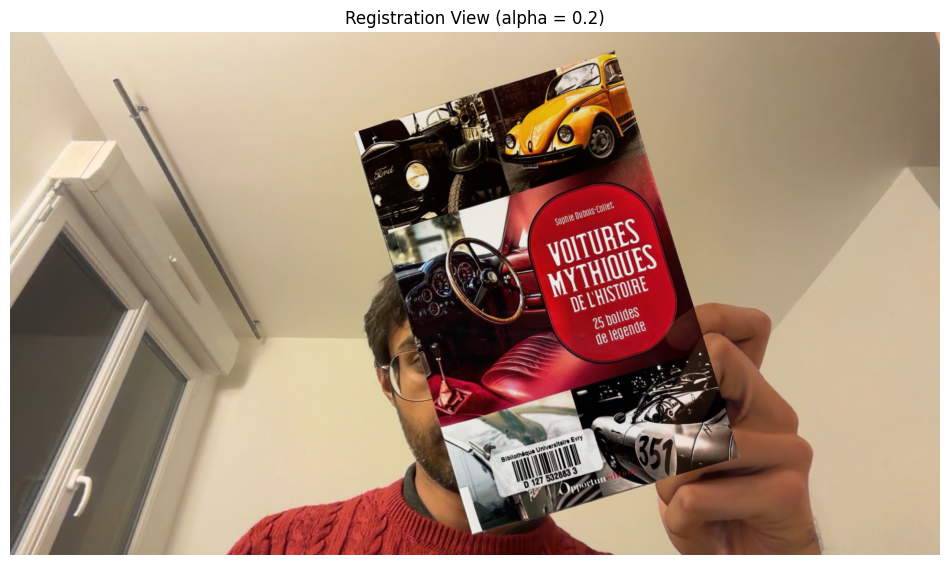

In [28]:
# Registration view: the marker itself warped onto the frame. If the
# homography is right, it lines up with the real marker (sharp, no ghosting)
warped_marker, marker_mask = warp_image(marker, homography, frame_width, frame_height)
registration_view = overlay_image(frame, warped_marker, marker_mask, config.FRAME_ALPHA)
plot_image(registration_view, f"Registration View (alpha = {config.FRAME_ALPHA})", 12)